In [1]:
#준비 셀 1. 데이터, 한 줄 추가
import torch
import torch.nn as nn
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split
device = "cuda" if torch.cuda.is_available() else "cpu"
torch.backends.cudnn.deterministic = True # 새 줄, GPU에서도 같은 seed면 같은 결과
train_all = datasets.MNIST(root="data", train=True, download=True,
 transform=transforms.ToTensor())
g = torch.Generator().manual_seed(0) # 학습과 검증 분리, seed 0
train_set, val_set = random_split(train_all, [50000, 10000], generator=g)
train_loader = DataLoader(train_set, batch_size=64, shuffle=True)
val_loader = DataLoader(val_set, batch_size=256, shuffle=False)
print(len(train_loader), len(val_loader)) # → 782 40

100.0%
100.0%
100.0%
100.0%

782 40


In [2]:
#준비 셀 2. Baseline MLP와 loss_fn
class MLP(nn.Module): # Baseline MLP 그대로
 def __init__(self):
        super().__init__()
        self.flat = nn.Flatten() # (N, 1, 28, 28) → (N, 784)
        self.fc1 = nn.Linear(784, 100)
        self.act = nn.ReLU()
        self.fc2 = nn.Linear(100, 10)
 def forward(self, x):
    x = self.flat(x)
    return self.fc2(self.act(self.fc1(x)))
loss_fn = nn.CrossEntropyLoss()
print(MLP()(torch.zeros(2, 1, 28, 28)).shape) # → torch.Size([2, 10])

torch.Size([2, 10])


In [4]:
#준비 셀 3-1. 검증 함수
def evaluate(model, loader): # 검증 함수, 그대로
    model.eval()
    total_loss, correct = 0.0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            total_loss += loss_fn(out, y).item() * len(y)
            correct += (out.argmax(dim=1) == y).sum().item()
    n = len(loader.dataset)
    return total_loss / n, correct / n * 100

In [5]:
#준비 셀 3-2. 학습 함수
def train_one_epoch(model, loader, opt): # 학습 함수, 그대로
    model.train()
    total_loss = 0.0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        loss = loss_fn(model(x), y)
        opt.zero_grad()
        loss.backward()
        opt.step()
        total_loss += loss.item() * len(y)
    return total_loss / len(loader.dataset)

In [6]:
#예제 5-1. 세로 경계 kernel과 가로 경계 kernel
import torch.nn.functional as F
img, label = train_all[0] # 첫 번째 학습 사진 (1, 28, 28)
x = img.view(1, 1, 28, 28) # (N, C, H, W), 1장짜리 배치
k_v = torch.tensor([[-1., 0., 1.],
 [-1., 0., 1.],
 [-1., 0., 1.]]) # 세로 경계 kernel
k_h = torch.tensor([[-1., -1., -1.],
 [ 0., 0., 0.],
 [ 1., 1., 1.]]) # 가로 경계 kernel
out_v = F.conv2d(x, k_v.view(1, 1, 3, 3)) # kernel 모양도 4차원
out_h = F.conv2d(x, k_h.view(1, 1, 3, 3))
print(label, x.shape) # → 5 torch.Size([1, 1, 28, 28])
print(out_v.shape) # → torch.Size([1, 1, 26, 26])

5 torch.Size([1, 1, 28, 28])
torch.Size([1, 1, 26, 26])


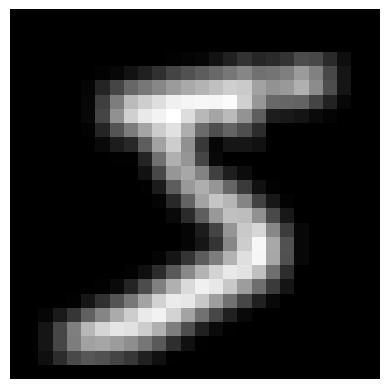

In [7]:
import matplotlib.pyplot as plt

#실습 1 셀. 첫 줄만 바꿔 가며 실행
k = torch.ones(3, 3) / 9 # 이 줄의 kernel만 바꿔 가며 실행한다
out = F.conv2d(x, k.view(1, 1, 3, 3)) # 예제 5-1의 사진 x에 적용
plt.imshow(out[0, 0], cmap="gray")
plt.axis("off")
plt.show()

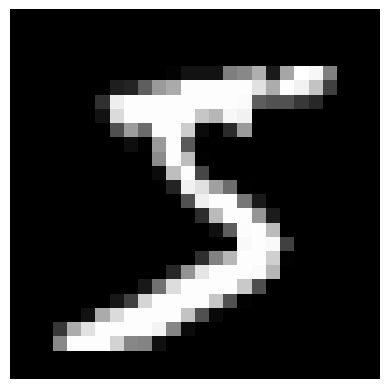

In [8]:
import matplotlib.pyplot as plt

#실습 1 셀. 첫 줄만 바꿔 가며 실행
k = torch.tensor([[0., 0., 0.],
 [0., 1., 0.],
 [0., 0., 0.]]) # 2. 가운데만 1
out = F.conv2d(x, k.view(1, 1, 3, 3)) # 예제 5-1의 사진 x에 적용
plt.imshow(out[0, 0], cmap="gray")
plt.axis("off")
plt.show()

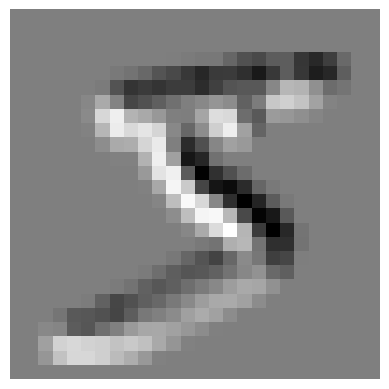

In [10]:
import matplotlib.pyplot as plt

#실습 1 셀. 첫 줄만 바꿔 가며 실행
k = torch.tensor([[ 0., 1., 1.],
 [-1., 0., 1.],
 [-1., -1., 0.]]) # 3. 대각선 경계, 한 가지 예
out = F.conv2d(x, k.view(1, 1, 3, 3)) # 예제 5-1의 사진 x에 적용
plt.imshow(out[0, 0], cmap="gray")
plt.axis("off")
plt.show()

In [11]:

#예제 5-2. 학습할 kernel 16개를 가진 계층
conv = nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3)
print(conv.weight.shape) # → torch.Size([16, 1, 3, 3]) (3×3 kernel 16개)
print(conv.bias.shape) # → torch.Size([16])
print(sum(p.numel() for p in conv.parameters())) # → 160 (16 × 9 + 16)
x, y = next(iter(train_loader)) # 배치 하나
print(x.shape) # → torch.Size([64, 1, 28, 28]) (N, C, H, W)
print(conv(x).shape) # → torch.Size([64, 16, 26, 26]) (feature map 16장씩)



torch.Size([16, 1, 3, 3])
torch.Size([16])
160
torch.Size([64, 1, 28, 28])
torch.Size([64, 16, 26, 26])


In [12]:
#예제 5-3. 컬러 사진 모양 (1, 3, 32, 32)에 적용
conv_rgb = nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3)
print(conv_rgb.weight.shape) # → torch.Size([16, 3, 3, 3]) (kernel 16개, 두께 3)
print(sum(p.numel() for p in conv_rgb.parameters())) # → 448 (16 × 27 + 16)
photo = torch.rand(1, 3, 32, 32) # 컬러 사진 1장 모양, 값은 무작위
print(conv_rgb(photo).shape) # → torch.Size([1, 16, 30, 30])

torch.Size([16, 3, 3, 3])
448
torch.Size([1, 16, 30, 30])


In [ ]:
#예제 5-3. 컬러 사진 모양 (1, 3, 32, 32)에 적용
conv_rgb = nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3)
print(conv_rgb.weight.shape) # → torch.Size([16, 3, 3, 3]) (kernel 16개, 두께 3)
print(sum(p.numel() for p in conv_rgb.parameters())) # → 448 (16 × 27 + 16)
photo = torch.rand(1, 3, 32, 32) # 컬러 사진 1장 모양, 값은 무작위
print(conv_rgb(photo).shape) # → torch.Size([1, 16, 30, 30]

In [13]:
#예제 5-3. 컬러 사진 모양 (1, 3, 32, 32)에 적용
conv_rgb = nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3)
print(conv_rgb.weight.shape) # → torch.Size([16, 3, 3, 3]) (kernel 16개, 두께 3)
print(sum(p.numel() for p in conv_rgb.parameters())) # → 448 (16 × 27 + 16)
photo = torch.rand(1, 3, 32, 32) # 컬러 사진 1장 모양, 값은 무작위
print(conv_rgb(photo).shape) # → torch.Size([1, 16, 30, 30])

torch.Size([16, 3, 3, 3])
448
torch.Size([1, 16, 30, 30])


In [14]:
#2와 3을 실행해서 검증
print(sum(p.numel() for p in nn.Linear(784, 100).parameters()))
# → 78500 (문제 2, 28×28)
print(sum(p.numel() for p in nn.Linear(280 * 280, 100).parameters()))
# → 7840100 (문제 2, 280×280, 약 100배)
print(sum(p.numel() for p in nn.Conv2d(1, 16, 3).parameters()))
# → 160 (문제 2, 사진 크기와 상관없다)
flat = torch.full((1, 1, 5, 5), 0.7) # 3. 고르게 0.7인 사진
print(F.conv2d(flat, k_v.view(1, 1, 3, 3)).view(-1).tolist())
# → [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
print(k_v.sum().item()) # → 0.0 (kernel 값의 합)

78500
7840100
160
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
0.0


In [15]:
conv = nn.Conv2d(1, 16, kernel_size=3)
conv(torch.zeros(64, 28, 28)) # 1. 채널 차원 없이 넣으면
# → RuntimeError: ... expected input[1, 64, 28, 28] to have 1 channels, but got 64 channels instead

RuntimeError: Given groups=1, weight of size [16, 1, 3, 3], expected input[1, 64, 28, 28] to have 1 channels, but got 64 channels instead

In [16]:
#예제 5-4. 같은 사진, 다른 설정 세 가지
x = torch.zeros(1, 1, 28, 28) # 사진 1장 모양
conv_a = nn.Conv2d(1, 8, kernel_size=3) # padding 없음
conv_b = nn.Conv2d(1, 8, kernel_size=3, padding=1) # 테두리 1칸
conv_c = nn.Conv2d(1, 8, kernel_size=3, padding=1, stride=2) # 2칸씩 이동
print(conv_a(x).shape) # → torch.Size([1, 8, 26, 26])
print(conv_b(x).shape) # → torch.Size([1, 8, 28, 28]) 크기 유지
print(conv_c(x).shape) # → torch.Size([1, 8, 14, 14]) 절반

torch.Size([1, 8, 26, 26])
torch.Size([1, 8, 28, 28])
torch.Size([1, 8, 14, 14])


In [ ]:
#예제 5-5. 다이어그램과 같은 값으로 확인
pool = nn.MaxPool2d(2) # 2×2 영역마다 최댓값 하나
t = torch.tensor([[1., 3., 2., 0.],
 [4., 2., 1., 1.],
 [0., 1., 5., 2.],
 [2., 0., 3., 4.]]).view(1, 1, 4, 4)
print(pool(t).view(2, 2).tolist()) # → [[4.0, 2.0], [2.0, 5.0]]
print(pool(torch.zeros(64, 16, 28, 28)).shape)
# → torch.Size([64, 16, 14, 14]) 채널 수는 그대로, 크기만 절반
print(sum(p.numel() for p in pool.parameters())) # → 0 파라미터 없음